# Oscar — 03: SVM (working)

Run `report/01-Data.ipynb` first.

Same features as the final LR (fixes 1-4 + ratios) and same 5 folds as `02`. Score to beat: LR CV AUC 0.7722. 

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import prep                         # Oscar/prep.py: fixes 1-4 + ratio features

raw_train, y_train = prep.load("train")
X = prep.prepare(raw_train, ratios=True)                    # fixes 1-3 + ratios; scaling is done inside each fold
cv = StratifiedKFold(5, shuffle=True, random_state=2026)    # same folds as 02

print("X:", X.shape, f"  {y_train.mean():.2%} defaulted")

X: (17997, 61)   22.12% defaulted


## 1. First look

Same test bench as `02` section 3. SVC gives scores, not probabilities, so AUC only for now (no log loss).

In [25]:
results, fold_auc = {}, {}      # name -> CV summary; name -> AUC on each fold

def cv_model(name, model):
    """5-fold CV AUC; standardising is learned inside each fold."""
    r = cross_validate(make_pipeline(StandardScaler(), model), X, y_train, cv=cv,
                       scoring="roc_auc", return_train_score=True)
    fold_auc[name] = r["test_score"]
    results[name] = {"auc": r["test_score"].mean(), "auc_sd": r["test_score"].std(),
                     "train_auc": r["train_score"].mean(), "fit_s": r["fit_time"].mean()}
    return pd.DataFrame.from_dict(results, orient="index").round(4)

def compare(ref="LR"):
    """AUC gain over `ref`, fold by fold: every model sat the same 5 folds."""
    gain = pd.DataFrame(fold_auc).sub(fold_auc[ref], axis=0)
    return pd.DataFrame({"mean gain": gain.mean(), "folds better": (gain > 0).sum()}).round(4)

cv_model("LR", LogisticRegression(C=0.0316, l1_ratio=0, solver="liblinear", max_iter=1000))   # final LR from 02
cv_model("SVM rbf (defaults)", SVC())                                                        # C=1, gamma="scale"

,auc,auc_sd,train_auc,fit_s
LR,0.7722,0.0140,0.7775,0.0676
SVM rbf (defaults),0.7244,0.0112,0.8528,3.2357


In [26]:
compare()

,mean gain,folds better
LR,0.0000,0
SVM rbf (defaults),-0.0478,0


Note here that the default radial basis function is worse that logistic regresstion on all 5 folds. We also see some overfitting from the SVM - train AUC of 0.85 and CV AUC of 0.72. Thus we look to provide less model flexibility below by tuning hyperparamters.

## 2. Tuning C and gamma

In [27]:
Cs = [0.01, 0.1, 1, 10]
gammas = [0.001, 0.003, 0.01, 0.03]     # default "scale" = 1 / (61 features x variance 1) ≈ 0.016

for C in Cs:                             # 16 settings x 5 folds; a few minutes
    for g in gammas:
        cv_model(f"rbf C={C} g={g}", SVC(C=C, gamma=g))

grid = pd.DataFrame([{"C": C, "gamma": g, **results[f"rbf C={C} g={g}"]} for C in Cs for g in gammas])
grid.pivot(index="C", columns="gamma", values="auc").round(4)

gamma,0.001,0.003,0.010,0.030
C,,,,
0.01,0.7569,0.7524,0.7432,0.7401
0.10,0.7576,0.7433,0.7381,0.7350
1.00,0.7273,0.7253,0.7245,0.7250
10.00,0.7232,0.7202,0.7134,0.7151


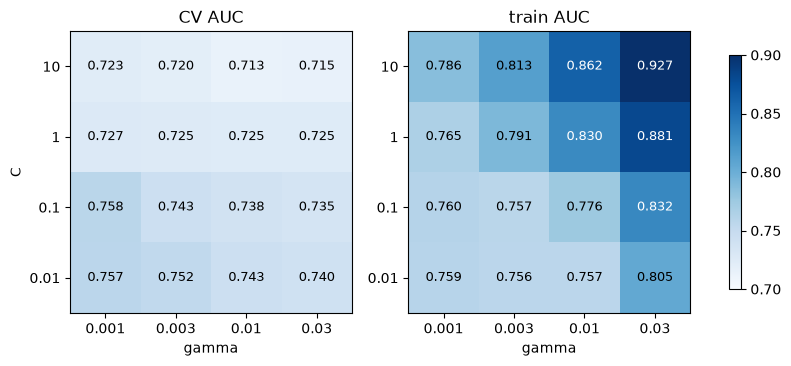

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, col, title in [(axes[0], "auc", "CV AUC"), (axes[1], "train_auc", "train AUC")]:
    t = grid.pivot(index="C", columns="gamma", values=col)
    im = ax.imshow(t, cmap="Blues", vmin=0.70, vmax=0.90, origin="lower")   # same scale on both panels
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            v = t.iloc[i, j]
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 0.82 else "black")
    ax.set(xticks=range(len(gammas)), xticklabels=gammas, yticks=range(len(Cs)), yticklabels=Cs,
           xlabel="gamma", title=title)
axes[0].set_ylabel("C")
fig.colorbar(im, ax=axes, shrink=0.8)

Pretty clear pattern: anything that makes the boundary more flexible (bigger gamma, bigger C) makes CV worse while train AUC shoots up (0.93 top right). So it's just memorising the training customers.

Best so far is C=0.1, gamma=0.001 at 0.758. Way better than the defaults (0.724) but still below LR. Also train ≈ CV here, so it's not overfitting any more, it's just a weaker fit than LR.

Best is sitting on the edge of the grid though (smallest gamma), so worth going a bit further before calling it.

In [29]:
# best was on the edge (smallest gamma): extend once; tiny gamma needs larger C to fit anything
Cs_ext, gammas_ext = [0.1, 1, 10], [0.0001, 0.0003]
for C in Cs_ext:
    for g in gammas_ext:
        cv_model(f"rbf C={C} g={g}", SVC(C=C, gamma=g))

grid = pd.DataFrame([{"C": float(k.split()[1][2:]), "gamma": float(k.split()[2][2:]), **v}
                     for k, v in results.items() if k.startswith("rbf C=")])
print(grid.pivot(index="C", columns="gamma", values="auc").round(4), "\n")
print(grid.pivot(index="C", columns="gamma", values="train_auc").round(4))

gamma  0.0001  0.0003  0.0010  0.0030  0.0100  0.0300
C                                                    
0.01      NaN     NaN  0.7569  0.7524  0.7432  0.7401
0.10   0.7583  0.7580  0.7576  0.7433  0.7381  0.7350
1.00   0.7584  0.7417  0.7273  0.7253  0.7245  0.7250
10.00  0.7306  0.7217  0.7232  0.7202  0.7134  0.7151 

gamma  0.0001  0.0003  0.0010  0.0030  0.0100  0.0300
C                                                    
0.01      NaN     NaN  0.7591  0.7565  0.7566  0.8054
0.10   0.7602  0.7600  0.7602  0.7574  0.7756  0.8324
1.00   0.7604  0.7546  0.7653  0.7910  0.8305  0.8808
10.00  0.7588  0.7665  0.7857  0.8126  0.8625  0.9272


In [30]:
best = grid.loc[grid["auc"].idxmax()]
print(f"best: C={best['C']}, gamma={best['gamma']}, CV AUC {best['auc']:.4f}\n")
compare().sort_values("mean gain", ascending=False).head(6)

best: C=1.0, gamma=0.0001, CV AUC 0.7584



,mean gain,folds better
LR,0.0000,0
rbf C=1 g=0.0001,-0.0138,0
rbf C=0.1 g=0.0001,-0.0139,1
rbf C=0.1 g=0.0003,-0.0143,1
rbf C=0.1 g=0.001,-0.0146,0
rbf C=0.01 g=0.001,-0.0153,1


Going smaller on gamma barely does anything: best is now C=1, gamma=0.0001 at 0.7584, only +0.0008, which is way inside the fold noise. So it's plateaued at ~0.758 and more tuning isn't going to save it. Still ~0.014 behind LR and better on at most 1/5 folds, so tuned rbf SVM doesn't beat LR.

With gamma this small the rbf kernel is basically linear, and train AUC (~0.76) is still below LR's (~0.78). So I don't think it's the shape of the boundary holding it back, more likely the loss. Hinge loss ignores customers already on the right side of the margin, whereas LR's log loss uses everyone. Going to check with a linear SVM next.

Bigger C at tiny gamma got worse, not better, which I didn't expect. Maybe chasing the misclassified customers messes up the ranking for everyone else?

## 3. Linear SVM: is it the loss?

In [31]:
from sklearn.svm import LinearSVC

# same linear boundary, three losses; same C means the same penalty on the weights in all three
# random_state: LinearSVC visits the customers in a random order, so fix it to get the same numbers each run
Cs_lin = [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 1e-2]
losses = {"hinge":         lambda C: LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000, random_state=2026),
          "squared hinge": lambda C: LinearSVC(C=C, loss="squared_hinge", dual=True, max_iter=20000, random_state=2026),
          "log (LR)":      lambda C: LogisticRegression(C=C, l1_ratio=0, solver="liblinear", max_iter=1000)}

for loss, make in losses.items():
    for C in Cs_lin:
        cv_model(f"{loss} C={C:g}", make(C))

lin = pd.DataFrame([{"loss": loss, "C": C, **results[f"{loss} C={C:g}"]} for loss in losses for C in Cs_lin])
lin.pivot(index="C", columns="loss", values="auc").round(4)

loss,hinge,log (LR),squared hinge
C,,,
0.00001,0.7619,0.7653,0.7706
0.00003,0.7657,0.7679,0.7733
0.00010,0.7630,0.7711,0.7744
0.00030,0.7411,0.7736,0.7738
0.00100,0.6470,0.7744,0.7728
0.01000,0.6221,0.7729,0.7719


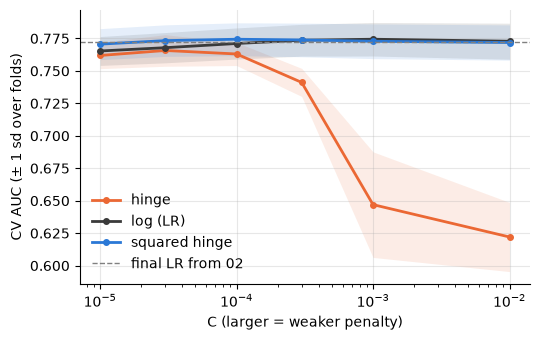

In [32]:
colours = {"hinge": "#eb6834", "squared hinge": "#2a78d6", "log (LR)": "#3a3a3a"}
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for loss, d in lin.groupby("loss"):
    ax.plot(d["C"], d["auc"], "o-", color=colours[loss], lw=2, ms=4, label=loss)
    ax.fill_between(d["C"], d["auc"] - d["auc_sd"], d["auc"] + d["auc_sd"], color=colours[loss], alpha=0.12, lw=0)
ax.axhline(results["LR"]["auc"], color="grey", ls="--", lw=1, label="final LR from 02")
ax.set(xscale="log", xlabel="C (larger = weaker penalty)", ylabel="CV AUC (± 1 sd over folds)")
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()

In [33]:
compare().loc[[f"{loss} C={C:g}" for loss in losses for C in Cs_lin]]

,mean gain,folds better
hinge C=1e-05,-0.0104,0
hinge C=3e-05,-0.0065,0
hinge C=0.0001,-0.0092,1
hinge C=0.0003,-0.0311,0
hinge C=0.001,-0.1252,0
hinge C=0.01,-0.1502,0
squared hinge C=1e-05,-0.0016,1
squared hinge C=3e-05,0.0011,2
squared hinge C=0.0001,0.0022,5
squared hinge C=0.0003,0.0016,5


Looks like it is the loss. Plain hinge is fine at tiny C (0.766) but falls off a cliff to ~0.62-0.65 as C goes up, whereas squared hinge and LR are pretty much the same line, both topping out at 0.7744. rbf SVC uses plain hinge, so this is probably what was capping it at ~0.758 in section 2, and why bigger C made it worse there. (The hinge numbers at big C move around a bit with the random seed and it throws convergence warnings there, so I wouldn't read anything into 0.62 vs 0.65, just that it collapses.)

I think the reason is what score each loss is aiming for. LR aims for log(p/(1-p)) and squared hinge for 2p-1, which both go up with p so people stay in order. Hinge just aims for +1 if p > 0.5 and -1 otherwise. Almost nobody here is above 0.5, so everyone gets pushed to the same score and the ordering gets lost, which is exactly what AUC measures. At tiny C the weights can't get big enough to do that, hence it only works there. (Zhang 2004, Bartlett, Jordan & McAuliffe 2006)

Also LR at C=0.001 gets 0.7744 too, better than my final LR from 02 (C=0.0316) on all 5 folds. In 02 I picked C on log loss, here it's AUC. So the SVM only ties with LR once LR is tuned properly, and which C is "best" depends on which metric we go with. Need to sort with the group.

## 4. Final SVM: probabilities and a validation check

In [34]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV

def platt(m):
    """Platt scaling: fit a sigmoid to the SVM's scores (on held-out parts of the training fold) to get probabilities."""
    return CalibratedClassifierCV(m, method="sigmoid", cv=5)

# best of each kind from sections 2-3, plus LR tuned on log loss (02) and on AUC (section 3)
finalists = {
    "rbf C=1 g=0.0001 + Platt":     platt(SVC(C=1, gamma=0.0001)),
    "hinge C=3e-5 + Platt":         platt(LinearSVC(C=3e-5, loss="hinge", dual=True, max_iter=20000, random_state=2026)),
    "squared hinge C=1e-4 + Platt": platt(LinearSVC(C=1e-4, dual=True, max_iter=20000, random_state=2026)),
    "LR C=0.0316":                  LogisticRegression(C=0.0316, l1_ratio=0, solver="liblinear", max_iter=1000),
    "LR C=0.001":                   LogisticRegression(C=0.001, l1_ratio=0, solver="liblinear", max_iter=1000),
}

rows = {}
for name, m in finalists.items():          # rbf + Platt is the slow one (~2 min)
    r = cross_validate(make_pipeline(StandardScaler(), m), X, y_train, cv=cv, scoring=["roc_auc", "neg_log_loss"])
    rows[name] = {"auc": r["test_roc_auc"].mean(), "logloss": -r["test_neg_log_loss"].mean()}
pd.DataFrame.from_dict(rows, orient="index").round(4)

,auc,logloss
rbf C=1 g=0.0001 + Platt,0.7586,0.4518
hinge C=3e-5 + Platt,0.7650,0.4475
squared hinge C=1e-4 + Platt,0.7743,0.4372
LR C=0.0316,0.7722,0.4358
LR C=0.001,0.7744,0.4531


In [35]:
# one check on validation: fit on all of train; test set not used (my submitted model is LR, report/05)
from sklearn.metrics import roc_auc_score, log_loss

raw_val, y_val = prep.load("validation")
X_val = prep.prepare(raw_val, ratios=True)

p_val = {}
for name in ["squared hinge C=1e-4 + Platt", "LR C=0.0316", "LR C=0.001"]:
    m = make_pipeline(StandardScaler(), clone(finalists[name])).fit(X, y_train)
    p_val[name] = m.predict_proba(X_val)[:, 1]
    print(f"{name:<30} AUC {roc_auc_score(y_val, p_val[name]):.4f}   log loss {log_loss(y_val, p_val[name]):.4f}")

squared hinge C=1e-4 + Platt   AUC 0.7824   log loss 0.4287
LR C=0.0316                    AUC 0.7816   log loss 0.4267
LR C=0.001                     AUC 0.7828   log loss 0.4414


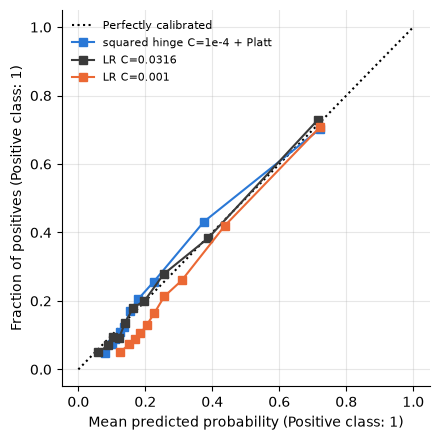

In [36]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(4.5, 4.5))
for name, c in [("squared hinge C=1e-4 + Platt", "#2a78d6"), ("LR C=0.0316", "#3a3a3a"), ("LR C=0.001", "#eb6834")]:
    CalibrationDisplay.from_predictions(y_val, p_val[name], n_bins=10, strategy="quantile", ax=ax, name=name, color=c)
ax.grid(alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

Platt scaling (Platt 1999) gives the SVMs probabilities so they can go on log loss too. In CV the squared hinge SVM gets AUC 0.7743 and log loss 0.4372, basically the same as LR on both. The rbf and plain hinge ones are worse on log loss as well as AUC (0.452 and 0.448), which makes sense since Platt can only rescale the scores, it can't put back ordering that's already been lost.

The two LRs show the AUC vs log loss thing really clearly. C=0.001 has the best AUC (0.7744) but much worse log loss (0.4531 vs 0.4358). Heavy penalty squashes everyone towards the base rate, which you can see in the calibration plot: the orange line sits below the diagonal, so it's overpredicting for the low and middle risk customers. Ranking is fine though, and AUC only cares about ranking. The SVM gets round this because Platt fits its own sigmoid afterwards, so it gets the heavy penalty AUC and decent probabilities at the same time.

On validation they're all within 0.001 AUC of each other (0.782-0.783), and LR C=0.0316 has the best log loss (0.4267, SVM 0.4287). So nothing here beats LR. I haven't used the test set, my submitted model is the LR in report/05.

## Summary

- Default rbf SVM is a lot worse than LR (0.724 vs 0.772) and overfits.
- Tuning C and gamma gets it to ~0.758 but it plateaus there, still behind LR on basically every fold.
- The thing holding it back is the hinge loss. Linear SVM with plain hinge collapses as C grows, squared hinge ties with LR.
- With Platt scaling the best SVM (squared hinge, C=1e-4) matches LR on AUC and log loss, but doesn't beat it, and it's an extra step for the same result. So sticking with LR as my model.
- Picking C on AUC vs log loss gives different "best" LRs (0.001 vs 0.0316), which is a decent example for the group's question about what the metric actually rewards.
- One thing not tested: rbf features with a better loss than hinge (e.g. Nystroem + LR). The rbf runs here all used hinge, so I can't fully rule out non-linearity helping. Left out for time.